# Spatiotemporal comparison of tissue morphodynamics between genotypes

<div style="background: linear-gradient(135deg, #1a1a2e 0%, #16213e 50%, #0f3460 100%); color: white; padding: 1.2em 1.8em; border-radius: 10px; margin-bottom: 1em;">

<p style="margin: 0 0 0.2em 0; font-weight: 300; font-size: 0.95em; letter-spacing: 0.05em; opacity: 0.85;">BELLAICHE LAB — Institut Curie</p>
<p style="margin: 0; font-size: 0.82em; opacity: 0.7;">Adrien Leroy, Eric van Leen, Maria Balakireva, Lale Alpar, Fabian Gärtner, Rémi Pigache, Isabelle Gaugué, Stéphane Pelletier, Mehdi Ech-Chouini, Julien Delpierre, Stéphane Rigaud, Floris Bosveld, Lorette Noiret, Yohanns Bellaïche</p>
<p style="margin: 0.1em 0 0 0; font-size: 0.75em; opacity: 0.5;">April 2026</p>

</div>

[Notebook 03](03_grn_analysis.ipynb) proposes candidate regulators for each morphodynamic domain. Here we test whether a gene drives the dynamics of its domain, comparing *TolloRNAi* (N = 5) with the *vRNAi* control (N = 8) on the pupal notum. The regulator's expression pattern is advected along the tissue flow, so it can be related to the phenotype at later time points.

The Global Moran's Index on the differential maps (*TolloRNAi* − *vRNAi*) finds *when* the phenotype is spatially coherent; LISA (Local Indicators of Spatial Association) finds *where*.

**Contents**

1. [Setup](#1.-Setup)
2. [Data loading](#2.-Data-loading)
3. [Global Moran's Index](#3.-Global-Moran's-Index)
4. [Differential maps at peak-MI time points](#4.-Differential-maps-at-peak-MI-time-points)
5. [LISA and ROI definition](#5.-LISA-and-ROI-definition)
6. [Quantification within ROIs](#6.-Quantification-within-ROIs)


## 1. Setup

In [1]:
import warnings

warnings.filterwarnings("ignore")

import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.ticker import MaxNLocator
import zarr
from skimage.measure import label as skimage_label

import napari

from pyanimalprocessing.spatial_statistics import (
    compute_moran,
    plot_moran,
    create_high_res_roi_outline,
    mask_and_crop_moran,
    per_animal_mean_over_roi,
    per_animal_weighted_mean_in_roi,
)
from pyanimalprocessing.plotting.comparison_plots import compare_genotypes_barplot
from pyanimalprocessing.plotting import read_property, plot_property
from pyanimalprocessing.plotting.napari_plotting import (
    add_tensor_legends,
    display_spatial_clusters,
)
from pyanimalprocessing.plotting.napari_export import save_viewer_state
from pyanimalprocessing.rescaling.timings import median_time, find_closest_time_index
from pyanimalprocessing.rescaling.geometry import (
    find_affine_transform,
    movie_frame_coordinate_system,
)

MORPHODOMAINS_ROOT = Path("..").resolve()
sys.path.insert(0, str(MORPHODOMAINS_ROOT))

from scripts.figures.figure_morphodynamics_comparison._helpers import (
    compute_moran_data,
    compute_contraction_roi,
    compute_flow_roi,
)

## 2. Data loading

The stores are those of [notebook 01](01_morphodynamic_domains.ipynb), on the common 40 µm grid, here with the 2 h window (241 time points over 22 h):

- **`241002_eulerian`** — PIV fields for both genotypes and their difference
- **`240920_lagrangian`** — the cell-tracked decomposition, for the time series within the ROIs
- **`210507_vi_pupa1`** — the reference movie the averages are projected onto

Each averaged store holds one group per genotype (`AOA_*`, animals on the last axis, index 0 = mean) and the difference (`DBA_*`, no animal axis):

```
241002_eulerian/EULERIAN/D2/
├── AOA_avgAnimals_vi_2h_0.96olap/          vRNAi      UPIV (241, 1, 40, 67, 2, 9), EpsilonPIV, …
├── AOA_avgAnimals_tolloi_2h_0.96olap/      TolloRNAi  same layout, animal axis of size 6
└── DBA_avgAnimals_Tolloi-avgAnimals_vi_2h_0.96olap/   TolloRNAi − vRNAi  UPIV (241, 1, 40, 67, 2), …
```

In [2]:
# Default: the Zenodo archive root (contains data/).  Override with MORPHODOMAINS_DATA.
DATA_ROOT = Path(
    os.environ.get(
        "MORPHODOMAINS_DATA",
        str(MORPHODOMAINS_ROOT.parents[1]),
    )
)

ZARR_ANIMAL = DATA_ROOT / "data/zarr/210507_vi_pupa1.zarr"
ZARR_EULERIAN = DATA_ROOT / "data/zarr/averages_v3/241002_eulerian"
ZARR_LAGRANGIAN = DATA_ROOT / "data/zarr/averages_v3/240920_lagrangian"

OUTPUT_BASE = Path("notebook_outputs") / "morphodynamics_comparison"
OUTPUT_BASE.mkdir(parents=True, exist_ok=True)
CACHE_DIR = OUTPUT_BASE / "cache"
CACHE_DIR.mkdir(exist_ok=True)

PVAL_THRESHOLD_ROI = 0.05
CONTRACTION_THRESHOLD = -0.02
# "largest" = pick the connected component with the most pixels after
# significance-masking.  Matches figure_morphodynamics_comparison's YAML config (roi_component_*:
# "largest"); passing an integer would select a specific scipy label,
# which is fragile to scan-order.
ROI_COMPONENT_DEFORMATION = "largest"
ROI_COMPONENT_VELOCITY = "largest"


animal = zarr.open_group(str(ZARR_ANIMAL), "r")
avgAnimal = zarr.open(str(ZARR_EULERIAN), mode="r")
avgAnimal_lagrangian = zarr.open(str(ZARR_LAGRANGIAN), mode="r")

# The averaged zarrs nest the backups under <MOTION>/D2/
AOA_vi = avgAnimal["EULERIAN"]["D2"]["AOA_avgAnimals_vi_2h_0.96olap"]
AOA_Tolloi = avgAnimal["EULERIAN"]["D2"]["AOA_avgAnimals_tolloi_2h_0.96olap"]
DBA_Tolloi_vi = avgAnimal["EULERIAN"]["D2"]["DBA_avgAnimals_Tolloi-avgAnimals_vi_2h_0.96olap"]

# Median time of each 2 h window (used by the Moran temporal axis)
time_frame = DBA_Tolloi_vi.attrs.asdict()["TimeArray"]
median_times = [median_time(f[0], f[1]) for f in time_frame]
n_timepoints = len(median_times)
print(f"Time points: {n_timepoints}")

# Geometry for mapping grid coordinates → image coordinates.  The grid start
# is read from the 15 hAPF spatial-transcriptome group (same grid used by
# figure_morphodynamics_comparison/preprocessing.py and by the atlas-advection helpers).
wt15h_zarr = animal.GEP.SPATIAL_TRANSCRIPTOME_15APF
overlap = np.array([0.5, 0.5, 0])
# Archetype box size in movie pixels (boxWidth/xFactor, boxHeight/yFactor):
# the same SAP rescaling read_property applies to place the average grid on this movie.
_, _, box_xyz, _ = movie_frame_coordinate_system(DBA_Tolloi_vi, reference_animal=animal)
boxsizes = np.array([box_xyz[:2]])
xy_starts_grid = np.array(
    [wt15h_zarr.attrs["grid_xStart"], wt15h_zarr.attrs["grid_yStart"]]
)
xy_starts = np.array([[animal.attrs["xStart"], animal.attrs["yStart"]]])

affine_transform = find_affine_transform(
    xy_starts_grid, xy_starts[0], overlap[:2], boxsizes[0][:2]
)

Time points: 241


## 3. Global Moran's Index

During which interval does *TolloRNAi* diverge from the control in a spatially coherent way? The Global Moran's Index (MI) measures the spatial autocorrelation of the differential field:

$$I = \frac{N}{W} \frac{\sum_i \sum_j w_{ij}(x_i - \bar{x})(x_j - \bar{x})}{\sum_i (x_i - \bar{x})^2}$$

where $x_i$ is the differential value in bin $i$, $w_{ij}$ the queen-contiguity weight (8 neighbours) and $W = \sum_{i,j} w_{ij}$. Computed at each time point, its maximum picks the frames used below.

In [3]:
moran_data = compute_moran_data(avgAnimal, animal)

moran_indices_epsilon = moran_data["moran_indices_epsilon"]
moran_indices_u = moran_data["moran_indices_u"]
max_idx_epsilon = moran_data["max_idx_epsilon"]
max_idx_u = moran_data["max_idx_u"]

print(
    f"Peak MI (deformation): {moran_indices_epsilon[max_idx_epsilon]:.3f} at t = {median_times[max_idx_epsilon]}"
)
print(
    f"Peak MI (velocity):    {moran_indices_u[max_idx_u]:.3f} at t = {median_times[max_idx_u]}"
)

Peak MI (deformation): 0.610 at t = 19h11
Peak MI (velocity):    0.801 at t = 18h43


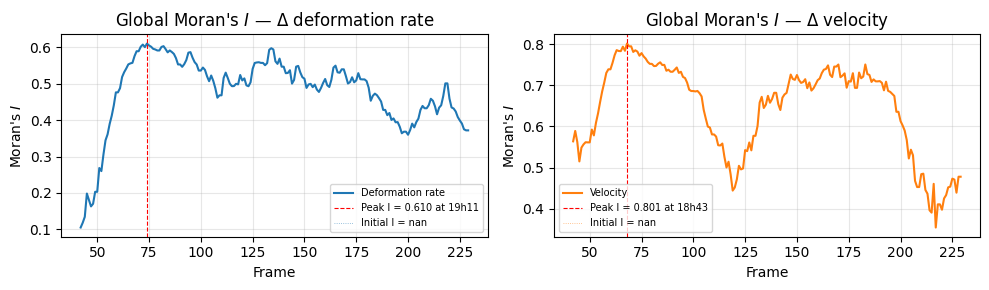

In [4]:
# Global Moran's I time-series: one trace per scalar field, peak marked
fig, (ax_eps, ax_u) = plt.subplots(1, 2, figsize=(10, 3))

for ax, mi, peak_idx, label, color in [
    (ax_eps, moran_indices_epsilon, max_idx_epsilon, "deformation rate", "#1f77b4"),
    (ax_u, moran_indices_u, max_idx_u, "velocity", "#ff7f0e"),
]:
    ax.plot(np.arange(len(mi)), mi, color=color, lw=1.5, label=label.capitalize())
    ax.axvline(
        peak_idx,
        color="red",
        ls="--",
        lw=0.8,
        label=f"Peak I = {mi[peak_idx]:.3f} at {median_times[peak_idx]}",
    )
    ax.axhline(
        mi[0], color=color, ls=":", lw=0.6, alpha=0.6, label=f"Initial I = {mi[0]:.3f}"
    )
    ax.set_xlabel("Frame")
    ax.set_ylabel("Moran's $I$")
    ax.set_title(f"Global Moran's $I$ — $\\Delta$ {label}")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

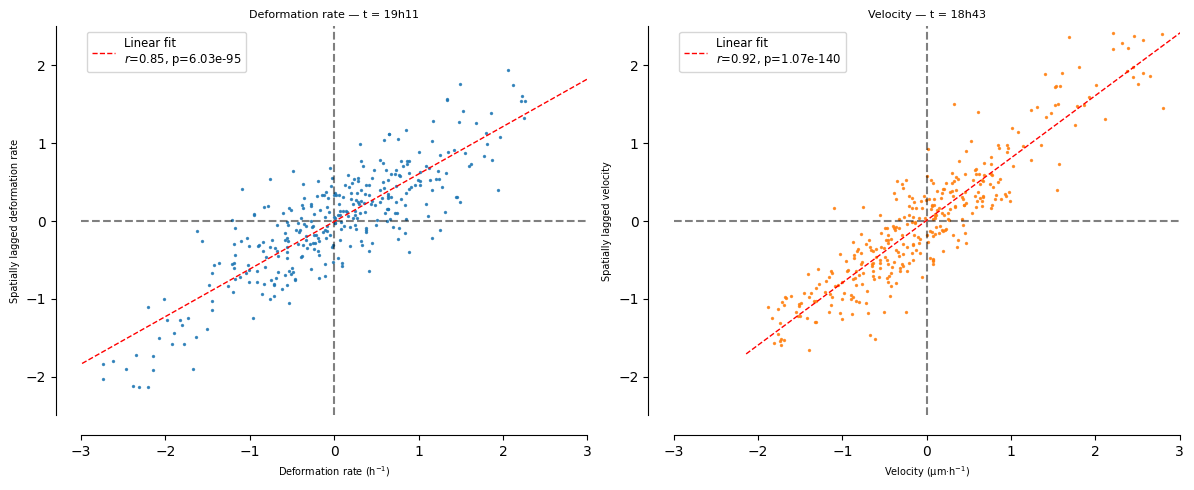

In [5]:
# Spatial autocorrelation scatterplots at the peak-MI frame.
# `compute_moran` and `plot_moran` are the public API from pyanimalprocessing.spatial_statistics.
data_epsilon_dba_iso = moran_data["data_epsilon_dba_iso"]
data_u_dba = moran_data["data_u_dba"]

fig, (ax_eps, ax_u) = plt.subplots(1, 2, figsize=(12, 5))

plot_moran(
    compute_moran(data_epsilon_dba_iso[max_idx_epsilon]),
    ax=ax_eps,
    scatter_kwds={"color": "#1f77b4", "s": 2, "alpha": 0.8},
    fit_kwds={"color": "red", "ls": "--", "lw": 1},
)
ax_eps.set_title(f"Deformation rate — t = {median_times[max_idx_epsilon]}", fontsize=8)
ax_eps.set_xlabel("Deformation rate (h$^{-1}$)", fontsize=7)
ax_eps.set_ylabel("Spatially lagged deformation rate", fontsize=7)

plot_moran(
    compute_moran(data_u_dba[max_idx_u]),
    ax=ax_u,
    scatter_kwds={"color": "#ff7f0e", "s": 2, "alpha": 0.8},
    fit_kwds={"color": "red", "ls": "--", "lw": 1},
)
ax_u.set_title(f"Velocity — t = {median_times[max_idx_u]}", fontsize=8)
ax_u.set_xlabel("Velocity (µm·h$^{-1}$)", fontsize=7)
ax_u.set_ylabel("Spatially lagged velocity", fontsize=7)

plt.tight_layout()
plt.show()

## 4. Differential maps at peak-MI time points

We display the *TolloRNAi* − *vRNAi* difference, stored in the `DBA_*` backup, at the frame where each phenotype is most coherent:

- **Velocity** ‖**u**‖ (µm h⁻¹), at `max_idx_u`
- **Isotropic deformation rate** tr(ε) (h⁻¹), at `max_idx_epsilon`

`read_property` keeps grid positions tracked in at least 60 % of animals and places the grid on the reference movie.

In [6]:
deformation_dba_fields = read_property(
    DBA_Tolloi_vi,
    "EpsilonPIV",
    reference_animal=animal,
    grid_bulk_threshold=0.6,
    significance=0,
)
velocity_dba_fields = read_property(
    DBA_Tolloi_vi,
    "UPIV",
    reference_animal=animal,
    grid_bulk_threshold=0.6,
    significance=0,
)

print(f"Spatial grid shape: {deformation_dba_fields['property_data'].shape[2:4]}")

Spatial grid shape: (40, 67)


### Visualising the differential fields

We render the velocity and isotropic deformation differentials on the reference tissue outline, each at its own peak-MI frame.

In [7]:
raw_outline = np.array(animal.IMAGE.D2.outlines).astype(float)
clean_outline = np.empty_like(raw_outline)
clean_outline[:] = np.nan
for i in range(raw_outline.shape[0]):
    tmp = skimage_label(raw_outline[i], connectivity=1)
    mask = tmp != 1
    clean_outline[i][mask] = raw_outline[i][mask]
np.nan_to_num(clean_outline, copy=False, nan=1.0)

viewer_velocity = napari.Viewer()
viewer_velocity.theme = "light"
viewer_velocity.add_image(clean_outline, name="outline")

<Image layer 'outline' at 0x7fbe855375b0>

In [8]:
plot_property(
    **{**velocity_dba_fields, "property_name": "Velocity (TolloRNAi − vRNAi)"},
    viewer=viewer_velocity,
    vector_scale=40,
    rescale_property="Rotation",
    vectors_kwargs={
        "edge_color": "#FF732E",
        "vector_style": "triangle",
        "edge_width": 5,
        "opacity": 1,
    },
)

add_tensor_legends(
    viewer_velocity,
    time_array=DBA_Tolloi_vi.attrs["TimeArray"],
    image_size=(2079, 3763),
    quantity="Velocity (TolloRNAi − vRNAi)",
    start_frame=int(round(np.asarray(velocity_dba_fields["affine_transform"])[0, -1])),
    quantity_color="#FF732E",
    quantity_anchor="lower_left",
    quantity_translation=[-250, 50],
    time_color="black",
    time_anchor="lower_left",
    time_translation=[-130, 50],
    legend_size=30,
)

In [9]:
viewer_deformation = napari.Viewer()
viewer_deformation.theme = "light"
viewer_deformation.add_image(clean_outline, name="outline")

<Image layer 'outline' at 0x7fbe1ddd5810>

In [10]:
plot_property(
    **{**deformation_dba_fields, "property_name": "Deformation rate (TolloRNAi − vRNAi)"},
    viewer=viewer_deformation,
    vector_scale=3000,
    scalar_scale=3000,
    rescale_property="Rotation",
    vectors_kwargs={
        "edge_color": "blue",
        "vector_style": "line",
        "edge_width": 8,
        "opacity": 1,
    },
)

add_tensor_legends(
    viewer_deformation,
    time_array=DBA_Tolloi_vi.attrs["TimeArray"],
    image_size=(2079, 3763),
    quantity="Deformation rate (TolloRNAi − vRNAi)",
    start_frame=int(round(np.asarray(deformation_dba_fields["affine_transform"])[0, -1])),
    quantity_color="blue",
    quantity_anchor="lower_left",
    quantity_translation=[-250, 50],
    time_color="black",
    time_anchor="lower_left",
    time_translation=[-130, 50],
    legend_size=30,
)

### Picking the peak-MI frame in viewer coordinates


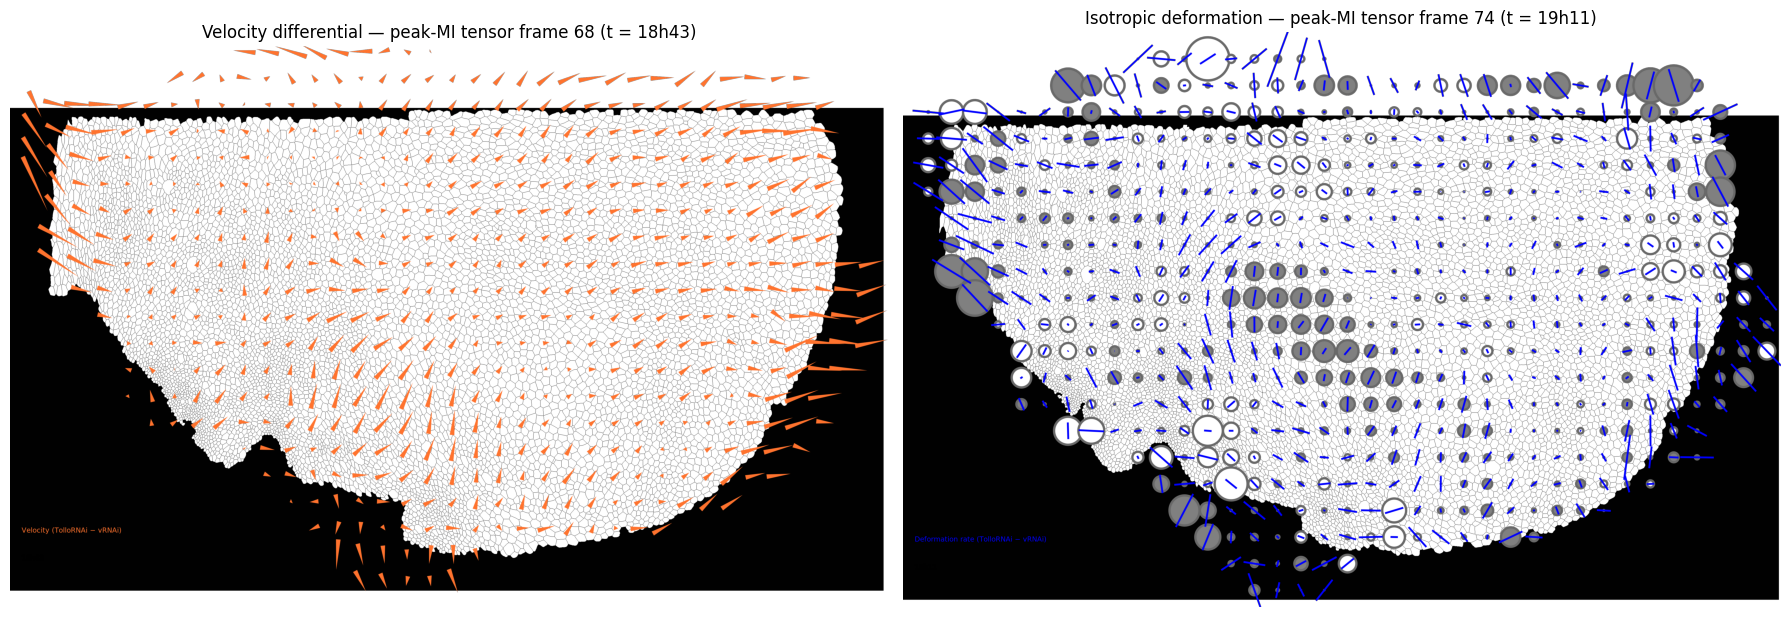

In [11]:
# Convert tensor index → world coord for the viewer.
# The `world_shift` is the raw-movie frame where tensor index 0 lives — the
# start-frame offset read_property put in the affine.  (The DBA backup's own
# FrameArray uses the Tolloi numbering, so it cannot be used here.)
world_shift = int(round(np.asarray(velocity_dba_fields["affine_transform"])[0, -1]))

save_viewer_state(
    viewer_velocity,
    str(OUTPUT_BASE / "dba_velocity.png"),
    frames=max_idx_u + world_shift,
    layers=[
        "outline",
        "Velocity (TolloRNAi − vRNAi)",
        "quantity legend",
        "median time legend",
    ],
)
save_viewer_state(
    viewer_deformation,
    str(OUTPUT_BASE / "dba_deformation.png"),
    frames=max_idx_epsilon + world_shift,
    layers=[
        "outline",
        "positive_Deformation rate (TolloRNAi − vRNAi) (shapes)",
        "negative_Deformation rate (TolloRNAi − vRNAi) (shapes)",
        "Deformation rate (TolloRNAi − vRNAi)_positive",
        "quantity legend",
        "median time legend",
    ],
)

# Viewers kept open; we add the ROI layers in §5 and re-screenshot.

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
axes[0].imshow(plt.imread(str(OUTPUT_BASE / "dba_velocity.png")))
axes[0].set_axis_off()
axes[0].set_title(
    f"Velocity differential — peak-MI tensor frame {max_idx_u} (t = {median_times[max_idx_u]})",
    fontsize=12,
)
axes[1].imshow(plt.imread(str(OUTPUT_BASE / "dba_deformation.png")))
axes[1].set_axis_off()
axes[1].set_title(
    f"Isotropic deformation — peak-MI tensor frame {max_idx_epsilon} (t = {median_times[max_idx_epsilon]})",
    fontsize=12,
)
plt.tight_layout()
plt.show()

## 5. LISA and ROI definition

LISA gives each bin a local index and a p-value, classifying it as High-High, Low-Low or an outlier (HL / LH):

$$I_i = \frac{(x_i - \bar{x})}{\hat{\sigma}^2} \sum_j w_{ij}(x_j - \bar{x})$$

Significance comes from a permutation test (`esda`); bins with $p <$ `PVAL_THRESHOLD_ROI` (0.05) form the ROIs:

- **Flow ROI** — the largest contiguous HH region of the velocity difference (*TolloRNAi* flows more).
- **Contraction ROI** — the largest contiguous LL region of the isotropic deformation difference (*TolloRNAi* contracts more).

Clusters and ROI outlines are overlaid on the viewers from §4. The LISA layers and the ROI outlines must use the same grid crop (`mask_and_crop_moran`), or the outlines drift; hence the single cell below.

Flow ROI:        52 bins at t = 18h43
Contraction ROI: 49 bins at t = 19h11


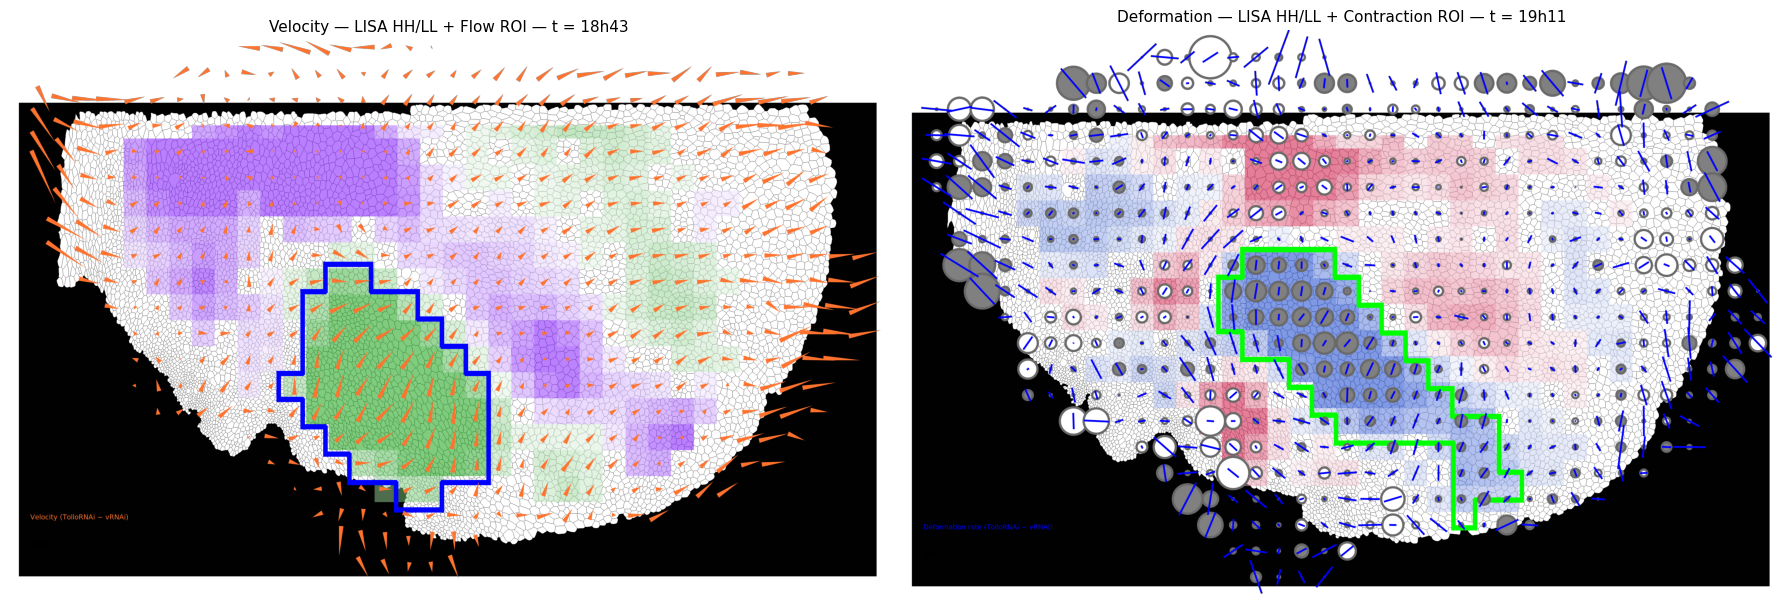

In [12]:
# Unpack LISA maps
p_values_epsilon = moran_data["p_values_epsilon"]
hh_map_epsilon = moran_data["hh_map_epsilon"]
ll_map_epsilon = moran_data["ll_map_epsilon"]

p_values_u = moran_data["p_values_u"]
hh_map_u = moran_data["hh_map_u"]
ll_map_u = moran_data["ll_map_u"]

# Dump raw LISA arrays + differential scalar fields to disk
lisa_dir = OUTPUT_BASE / "moran_plots"
lisa_dir.mkdir(parents=True, exist_ok=True)
for key in (
    "p_values_epsilon",
    "p_values_u",
    "hh_map_epsilon",
    "ll_map_epsilon",
    "hl_map_epsilon",
    "lh_map_epsilon",
    "hh_map_u",
    "ll_map_u",
    "hl_map_u",
    "lh_map_u",
    "data_epsilon_dba_iso",
    "data_u_dba",
):
    np.save(lisa_dir / f"{key}.npy", moran_data[key])

# ── 1. Crop the grid to the tissue extent ──────────────────────────────────
# `mask_and_crop_moran` NaN-outs grid bins whose image-space centres fall
# outside the tissue image and returns the cropped indices + adjusted affine.
# Both Moran arrays live on the same (T, 40, 67) grid, so one crop suffices.
IMAGE_SIZE = clean_outline.shape[-2:]  # (ny, nx)
p_u_viz, crop_y, crop_x, affine_viz = mask_and_crop_moran(
    p_values_u,
    affine_transform,
    masks=[],
    image_size=IMAGE_SIZE,
)
p_eps_viz = p_values_epsilon[:, crop_y, crop_x]

# ── 2. LISA HH / LL overlays on both viewers ───────────────────────────────
# `display_spatial_clusters` encodes -log10(p * cluster_map) so significant
# bins read darker under the chosen colormap.
display_spatial_clusters(
    viewer_velocity,
    p_u_viz,
    hh_map_u[:, crop_y, crop_x],
    "u_HH",
    "I Forest",
    affine_viz,
    time_offset=world_shift,
)
display_spatial_clusters(
    viewer_velocity,
    p_u_viz,
    ll_map_u[:, crop_y, crop_x],
    "u_LL",
    "I Purple",
    affine_viz,
    time_offset=world_shift,
)
display_spatial_clusters(
    viewer_deformation,
    p_eps_viz,
    hh_map_epsilon[:, crop_y, crop_x],
    "epsilon_HH",
    "I Bordeaux",
    affine_viz,
    time_offset=world_shift,
)
display_spatial_clusters(
    viewer_deformation,
    p_eps_viz,
    ll_map_epsilon[:, crop_y, crop_x],
    "epsilon_LL",
    "I Blue",
    affine_viz,
    time_offset=world_shift,
)

# ── 3. Compute the two ROIs on the full grid ───────────────────────────────
roi_flow = compute_flow_roi(
    p_values_u,
    hh_map_u,
    max_idx_u,
    pval_threshold=PVAL_THRESHOLD_ROI,
    roi_component=ROI_COMPONENT_VELOCITY,
    cache_dir=str(CACHE_DIR),
)
roi_contraction = compute_contraction_roi(
    p_values_epsilon,
    ll_map_epsilon,
    max_idx_epsilon,
    pval_threshold=PVAL_THRESHOLD_ROI,
    roi_component=ROI_COMPONENT_DEFORMATION,
    cache_dir=str(CACHE_DIR),
)
np.save(CACHE_DIR / "flow_roi.npy", roi_flow)
np.save(CACHE_DIR / "max_idx_u.npy", np.array(max_idx_u))
np.save(CACHE_DIR / "restrictive_roi.npy", roi_contraction)
np.save(CACHE_DIR / "max_idx_epsilon.npy", np.array(max_idx_epsilon))

indices_flow = np.array(np.where(roi_flow)).T
indices_contraction = np.array(np.where(roi_contraction)).T
print(f"Flow ROI:        {indices_flow.shape[0]} bins at t = {median_times[max_idx_u]}")
print(
    f"Contraction ROI: {indices_contraction.shape[0]} bins at t = {median_times[max_idx_epsilon]}"
)

# ── 4. ROI outlines overlaid on the cropped grid ───────────────────────────
# The crop MUST match the one used for the LISA overlay above, otherwise the
# upscaled outline drifts relative to the cluster image.
UPSCALE = 20
_scale_m = np.eye(3)
_scale_m[0, 0] = _scale_m[1, 1] = 1 / UPSCALE
_translate_m = np.eye(3)
_translate_m[0, -1] = _translate_m[1, -1] = -(UPSCALE - 1) / 2


def _roi_layer(roi_slice_viz, name):
    outline_hi = create_high_res_roi_outline(
        roi_slice_viz, upscale_factor=UPSCALE, outline_width=5
    )
    labels = np.zeros(
        (world_shift + p_values_u.shape[0],) + outline_hi.shape, dtype=np.float16
    )
    labels[:] = outline_hi
    labels[labels == 0] = np.nan
    return labels


# Flow ROI — plain affine (figure_morphodynamics_comparison velocity_difference pattern)
flow_slice_viz = roi_flow[max_idx_u][crop_y, crop_x]
flow_affine = affine_viz @ _scale_m @ _translate_m
viewer_velocity.add_image(
    _roi_layer(flow_slice_viz, "Flow ROI"),
    name="Flow ROI",
    affine=flow_affine,
    colormap="blue",
)

# Contraction ROI — extra 1.02 vertical scaling (figure_morphodynamics_comparison deformation pattern)
contraction_slice_viz = roi_contraction[max_idx_epsilon][crop_y, crop_x]
_vertical_m = np.eye(3)
_vertical_m[0, 0] *= 1.02
contraction_affine = affine_viz @ _scale_m @ _translate_m @ _vertical_m
viewer_deformation.add_image(
    _roi_layer(contraction_slice_viz, "Contraction ROI"),
    name="Contraction ROI",
    affine=contraction_affine,
    colormap="green",
)

# ── 5. Screenshot both viewers with LISA + ROI overlaid ────────────────────
save_viewer_state(
    viewer_velocity,
    str(OUTPUT_BASE / "lisa_flow.png"),
    frames=max_idx_u + world_shift,
    layers=[
        "outline",
        "u_HH",
        "u_LL",
        "Flow ROI",
        "Velocity (TolloRNAi − vRNAi)",
        "quantity legend",
        "median time legend",
    ],
)
save_viewer_state(
    viewer_deformation,
    str(OUTPUT_BASE / "lisa_contraction.png"),
    frames=max_idx_epsilon + world_shift,
    layers=[
        "outline",
        "epsilon_HH",
        "epsilon_LL",
        "Contraction ROI",
        "positive_Deformation rate (TolloRNAi − vRNAi) (shapes)",
        "negative_Deformation rate (TolloRNAi − vRNAi) (shapes)",
        "Deformation rate (TolloRNAi − vRNAi)_positive",
        "quantity legend",
        "median time legend",
    ],
)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
axes[0].imshow(plt.imread(str(OUTPUT_BASE / "lisa_flow.png")))
axes[0].set_axis_off()
axes[0].set_title(
    f"Velocity — LISA HH/LL + Flow ROI — t = {median_times[max_idx_u]}",
    fontsize=11,
)
axes[1].imshow(plt.imread(str(OUTPUT_BASE / "lisa_contraction.png")))
axes[1].set_axis_off()
axes[1].set_title(
    f"Deformation — LISA HH/LL + Contraction ROI — t = {median_times[max_idx_epsilon]}",
    fontsize=11,
)
plt.tight_layout()
plt.show()

### 5.1 Atlas *Tollo* expression pattern

`generate_atlas_advection_pattern` places the atlas *Tollo* pattern (`data/morphology/atlas_validation.txt`) on the tissue at 16h00 and transports it along the flow with the tracking masks, so it can be compared with the flow ROI at the same frame.

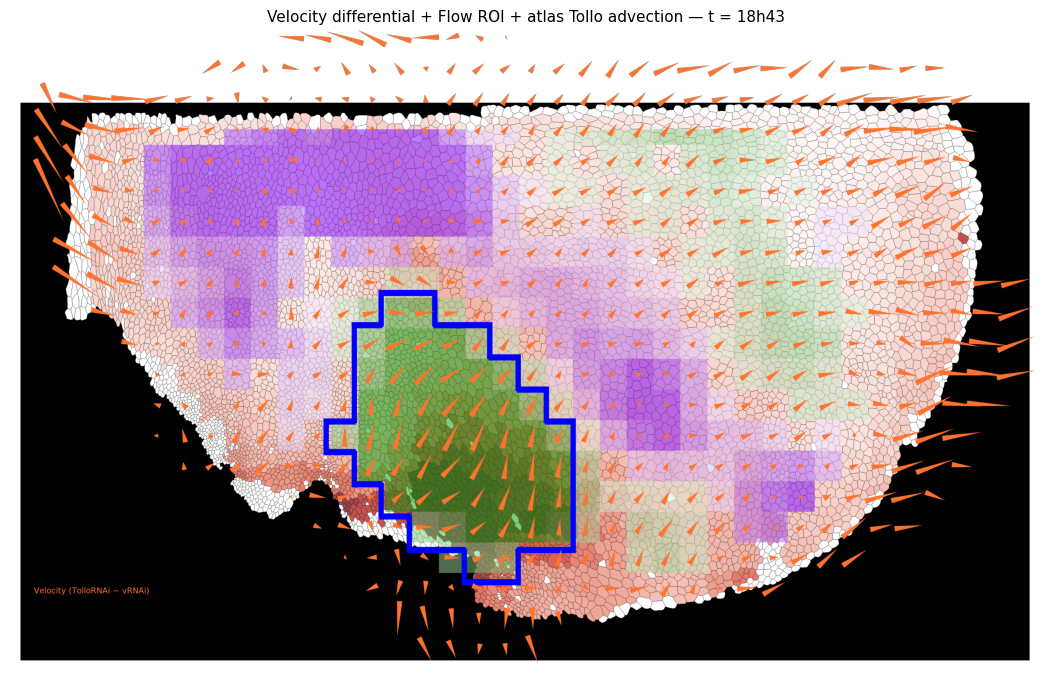

In [13]:
from scripts.figures.figure_morphodynamics_comparison._helpers import generate_atlas_advection_pattern
from pyanimalprocessing.rescaling.timings import find_frame
from vgep.plotter.palettes import WHITE_TO_RED, mpl_to_napari
from vgep.processing import normalize_01

dt = animal.attrs["dt"]
temperature = animal.attrs["temperature"]
time_ref = animal.attrs["timeRef"]
frame_ref_old = animal.attrs["frameRef"]
advection_frame_ref = int(
    np.array(find_frame(frame_ref_old, time_ref, temperature, "16h00", dt))[0]
)
tracking_mask = np.array(animal["TRACKING"]["masks_division_agnostic"])

atlas_path = DATA_ROOT / "data/morphology/atlas_validation.txt"
atlas_tollo_pattern = generate_atlas_advection_pattern(
    atlas_path,
    "Tollo",
    xy_starts_grid=xy_starts_grid,
    xy_start=xy_starts[0],
    overlap=0.5,
    boxsize=boxsizes[0],
    tracking_mask=tracking_mask,
    frame_ref=advection_frame_ref,
)

# Overlay the advected pattern on the flow viewer, matching figure_morphodynamics_comparison's style
_white_to_red_napari = mpl_to_napari(WHITE_TO_RED, "white_to_red_nb04")
viewer_velocity.add_image(
    normalize_01(atlas_tollo_pattern),
    name="Atlas Tollo Expression",
    colormap=_white_to_red_napari,
    contrast_limits=(0, 1),
    opacity=0.8,
)

save_viewer_state(
    viewer_velocity,
    str(OUTPUT_BASE / "flow_tollo.png"),
    frames=max_idx_u + world_shift,
    layers=[
        "outline",
        "Atlas Tollo Expression",
        "u_HH",
        "u_LL",
        "Flow ROI",
        "Velocity (TolloRNAi − vRNAi)",
        "quantity legend",
        "median time legend",
    ],
)

fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(plt.imread(str(OUTPUT_BASE / "flow_tollo.png")))
ax.set_axis_off()
ax.set_title(
    f"Velocity differential + Flow ROI + atlas Tollo advection — t = {median_times[max_idx_u]}",
    fontsize=11,
)
plt.tight_layout()
plt.show()

# Viewers no longer needed beyond this point — close them.
viewer_velocity.close()
viewer_deformation.close()

## 6. Quantification within ROIs

Within each ROI, per-animal values are compared between genotypes with a Mann-Whitney U test (`compare_genotypes_barplot`; ** p < 0.01, * p < 0.05). Values come from `per_animal_mean_over_roi` (Eulerian fields) and `per_animal_weighted_mean_in_roi` (Lagrangian fields, weighted by `AreaRatios`).

### 6.1 Velocity in the flow ROI

The polar arrows below show the mean displacement vector per genotype, not the signed average speed — they answer *"does TolloRNAi flow in a different direction?"*. The amplitude bar plot below compares per-animal flow magnitudes.


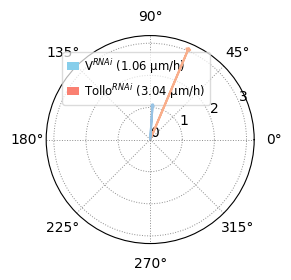

In [14]:
# Per-animal mean velocity vector (image-space y, x) inside the flow ROI
vecs_vi = per_animal_mean_over_roi(
    AOA_vi, "UPIV", roi_flow, component="dev"
)
vecs_tolloi = per_animal_mean_over_roi(
    AOA_Tolloi, "UPIV", roi_flow, component="dev"
)

# Match the paper's convention: reverse component order + flip the vertical sign
avg_vi = np.mean(vecs_vi[:, ::-1], axis=0)
avg_vi[1] = -avg_vi[1]
avg_tolloi = np.mean(vecs_tolloi[:, ::-1], axis=0)
avg_tolloi[1] = -avg_tolloi[1]
mag_vi, angle_vi = np.linalg.norm(avg_vi), np.arctan2(avg_vi[1], avg_vi[0])
mag_tolloi, angle_tolloi = np.linalg.norm(avg_tolloi), np.arctan2(
    avg_tolloi[1], avg_tolloi[0]
)

fig = plt.figure(figsize=(3, 3))
ax = plt.subplot(111, projection="polar")
ax.set_facecolor("white")
ax.arrow(
    angle_tolloi,
    0,
    0,
    mag_tolloi,
    head_width=0.05,
    head_length=0.05,
    fc="#F8AE8B",
    ec="#F8AE8B",
    linewidth=1.5,
    zorder=10,
)
ax.arrow(
    angle_vi,
    0,
    0,
    mag_vi,
    head_width=0.05,
    head_length=0.05,
    fc="#98C3E4",
    ec="#98C3E4",
    linewidth=1.5,
    zorder=10,
)
ax.set_ylim(0, max(mag_vi, mag_tolloi) + 0.2)
ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
ax.grid(True, linestyle=":", alpha=0.9, color="gray", linewidth=0.7)
ax.legend(
    handles=[
        mpatches.Patch(facecolor="skyblue", label=f"V$^{{RNAi}}$ ({mag_vi:.2f} µm/h)"),
        mpatches.Patch(
            facecolor="salmon", label=f"Tollo$^{{RNAi}}$ ({mag_tolloi:.2f} µm/h)"
        ),
    ],
    loc="upper left",
    bbox_to_anchor=(0.05, 0.95),
    framealpha=0.7,
    fontsize="small",
    handlelength=1.0,
    handletextpad=0.5,
)
plt.tight_layout()
plt.show()

Mann-Whitney velocity amplitude: p = 0.04507


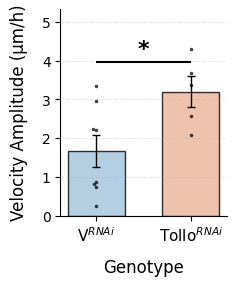

In [15]:
# Velocity amplitude — Mann-Whitney barplot using the same per-animal vectors
amp_vi = np.linalg.norm(vecs_vi[:, ::-1], axis=1)
amp_tolloi = np.linalg.norm(vecs_tolloi[:, ::-1], axis=1)

fig, p = compare_genotypes_barplot(
    amp_vi, amp_tolloi, ylabel="Velocity Amplitude (µm/h)"
)
print(f"Mann-Whitney velocity amplitude: p = {p:.4g}")
plt.show()

### 6.2 Isotropic deformation rate in the contraction ROI

Mean isotropic contraction rate (h⁻¹, reported as a positive number) within the contraction ROI at the peak-MI time window.


Mann-Whitney contraction: p = 0.003108


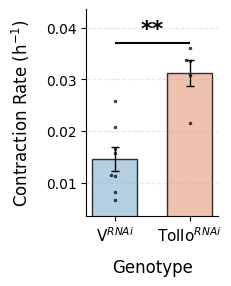

In [16]:
iso_vi = per_animal_mean_over_roi(
    AOA_vi, "EpsilonPIV", roi_contraction, component="iso"
)
iso_tolloi = per_animal_mean_over_roi(
    AOA_Tolloi, "EpsilonPIV", roi_contraction, component="iso"
)

fig, p = compare_genotypes_barplot(
    -iso_vi, -iso_tolloi, ylabel=r"Contraction Rate (h$^{-1}$)"
)
print(f"Mann-Whitney contraction: p = {p:.4g}")
plt.show()

### 6.3 Confirmatory Lagrangian quantities in the flow ROI

To check that the flow phenotype is bulk displacement rather than cell-shape change, apoptosis or rearrangement, we compare three Lagrangian quantities in the same ROI at the peak-MI time:

- **R → elongation** — eigenvalue difference of ER
- **S → contraction** — negated trace of ES
- **Apoptosis rate** — dnA normalised by the cell count (nCoreRNs) at 16h47

Mann-Whitney ER anisotropy: p = 0.1709


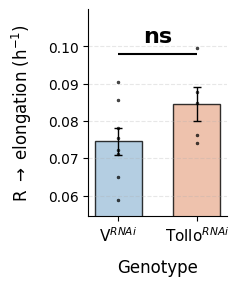

Mann-Whitney ES trace: p = 0.9433


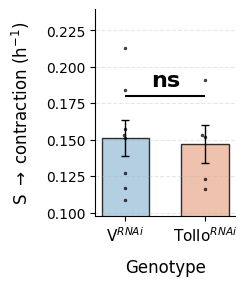

Mann-Whitney dnA : p = 1


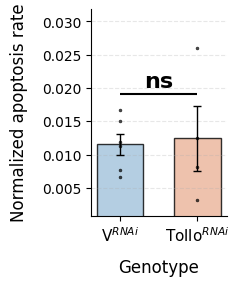

In [17]:
# The Lagrangian peak time is picked by matching the Moran U peak to the
# closest Lagrangian 2 h-window median time.
peak_time = moran_data["median_times"][max_idx_u]
roi_2d = roi_flow[max_idx_u]


def _t_idx_in(backup):
    meds = [median_time(f[0], f[1]) for f in backup.attrs["TimeArray"]]
    return find_closest_time_index(peak_time, meds)


def _ncorerns_broadcast(lag_zarr, geno):
    inst = lag_zarr["LAGRANGIAN_TRACKING"]["D2"][f"AOA_avgAnimals_{geno}_0h_0olap"]
    medians = [median_time(f[0], f[1]) for f in inst.attrs["TimeArray"]]
    ref_idx = find_closest_time_index("16h47", medians)
    # (T, 1, ny, nx, 1, N) → per-animal (ny, nx, N−1) map at the reference
    # time; broadcasts over the tensor's time axis inside the helper.
    return inst["nCoreRNs"][ref_idx, 0, :, :, 0, 1:]


def _compare(tensor_name, matrix_op, ylabel, *, negate=False, normalize=False):
    vals = {}
    for geno in ("vi", "tolloi"):
        backup = avgAnimal_lagrangian["LAGRANGIAN_TRACKING"]["D2"][
            f"AOA_avgAnimals_{geno}_2h_0.96olap"
        ]
        normalizer = None
        if normalize:
            normalizer = _ncorerns_broadcast(avgAnimal_lagrangian, geno)
        vals[geno] = per_animal_weighted_mean_in_roi(
            backup,
            tensor_name,
            roi_2d,
            _t_idx_in(backup),
            matrix_op=matrix_op,
            normalizer=normalizer,
        )
    clean_vi = vals["vi"][~np.isnan(vals["vi"])]
    clean_tolloi = vals["tolloi"][~np.isnan(vals["tolloi"])]
    if negate:
        clean_vi, clean_tolloi = -clean_vi, -clean_tolloi
    fig, p = compare_genotypes_barplot(clean_vi, clean_tolloi, ylabel=ylabel)
    print(f"Mann-Whitney {tensor_name} {matrix_op or ''}: p = {p:.4g}")
    return fig


_compare("ER", "anisotropy", r"R $\to$ elongation (h$^{-1}$)")
plt.show()
_compare("ES", "trace", r"S $\to$ contraction (h$^{-1}$)", negate=True)
plt.show()
_compare("dnA", None, "Normalized apoptosis rate", normalize=True)
plt.show()